# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [2]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [4]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [5]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [6]:
# mostrar las primeras 5 filas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [7]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [8]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [9]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [10]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [11]:
# cantidad de nulos para users
users.isna().sum()
users.isna().mean()

user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64

In [12]:
# cantidad de nulos para usage
usage.isna().sum
usage.isna().mean()

id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64

✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

* En el dataset `users`, la columna `churn_date` presenta casi un 89% de valores nulos, superando el umbral recomendado para considerar su eliminación o exclusión del análisis. Sin embargo, no considero conveniente eliminarla, ya que estos valores faltantes podrían indicar que la mayoría de los clientes aún mantienen activo su servicio. Por lo tanto, eliminar esta columna podría representar una pérdida de información importante para analizar la retención de clientes.
* La columna `city` del dataset `users` presenta aproximadamente un 12% de registros sin información. Recomiendo investigar si es posible recuperar estos datos faltantes, ya que eliminar los registros de estos clientes podría afectar el análisis de segmentación geográfica.
* La columna date presenta un porcentaje muy bajo de valores nulos, inferior al 5%, por lo que inicialmente podrían conservarse. Sin embargo, si no es posible recuperar esta información, se recomienda eliminar únicamente los registros que no tengan fecha, ya que esta variable es importante para identificar patrones de consumo a lo largo del tiempo.
* La columna duration presenta aproximadamente un 55% de valores nulos. Sin embargo, es necesario analizarla con mayor profundidad, ya que el dataset contiene registros tanto de llamadas como de mensajes. Si los valores nulos corresponden a mensajes, podrían considerarse valores faltantes esperados, por lo que no sería necesario eliminarlos ni reemplazarlos.
* La columna length presenta aproximadamente un 45% de valores nulos. Este caso podría ser contrario al de duration, ya que los valores faltantes podrían corresponder a registros de llamadas. De confirmarse esta relación, también se considerarían valores nulos esperados y no requerirían tratamiento adicional.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [13]:
# explorar columnas numéricas de users
users[['user_id','age']].describe()


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` no se observan sentinels, pero se debe identificar si hay duplicidad de valores ya que esta columna es un identificador unico.
- La columna `age` se evidencia sentinel (-999)lo debemos reemplazar por NaN y std la veo un poco elevada lo que podria significar que esta distorcionada por los valores invalidos.

In [14]:
# explorar columnas numéricas de usage
usage[['id','user_id','duration','length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`ambas columnas no presentan sentinels evidentes ni valores negativos y funcionan como identificadores. Se recomienda verificar posibles duplicados en id y comprobar que los valores de user_id correspondan a clientes registrados en el DataFrame users.
- La columna `duration` presenta un promedio (5.20) mayor que la mediana (3.50), lo que sugiere una distribución sesgada hacia la derecha (right-skewed), con posible presencia de outliers. Se recomienda investigar los valores extremos antes de decidir si requieren algún tratamiento.
- La columna `length` presenta un promedio (52.13) y una mediana (50) similares, lo que sugiere que los valores centrales están relativamente equilibrados. Sin embargo, la desviación estándar (56.61) y el valor máximo (1,490) indican una posible dispersión considerable y presencia de valores atípicos. Se recomienda investigar estos valores antes de aplicar algún tratamiento.

In [15]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for columna in columnas_user:
    print(columna)
    print(users[columna].unique())


city
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
plan
['Basico' 'Premium']


- La columna `city` se refleja la presencia del sentinel (?) que se debe reemplazar por NaN para que se reconozca de manera correcta, se deben estandarizar los nombres de las ciudades, especialmente aquellas que estan con abreviatura.
- La columna `plan` no se refleja presencia de sentinels ni valores invalidos, debe haber relacion con el DF de plans.

In [16]:
# explorar columna categórica de usage
usage['type'].unique()


array(['call', 'text'], dtype=object)

- La columna `type` muestra las dos categorias que mencionamos anteriormente (text y call), no se ven valores invalidos ni sentinels, conservar sin modificaciones.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [17]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'],errors='coerce')

In [18]:

# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'],errors='coerce')


In [19]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date` se identifican 40 registros correspondientes al 2026 incosistentes ya que los datos estan registrados hasta el 2024, de no ser posible recuperar esta informacion se podria reemplzar con NaT

In [20]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts().sort_index()

2024.0    39950
Name: date, dtype: int64

En `date` e identificaron 39,950 registros correspondientes al año 2024, sin evidenciar fechas fuera del período esperado entre los valores válidos. Sin embargo, existen 50 registros sin fecha válida, por lo que se recomienda investigar su origen y considerar su eliminación del análisis temporal si no es posible recuperar la información. 
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [21]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age']!= -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [22]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [23]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].isna().sum()

40

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [24]:
# Verificación MAR en usage (Missing At Random) para duration
def calcular_nulos(x):
    return x.isna().mean()
usage.groupby('type')['duration'].apply(calcular_nulos)

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [25]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(calcular_nulos)


type
call    0.99933
text    0.00000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`, los valores nulos tienen relacion directa con el tipo de actividad clasificandose como MAR y se pueden considerar valores faltantes esperados, evitando imputar o eliminar ya que afectaria el analisis del consumo, por lo tanto se evidencia q en duration aprox el 99% de los mensajes tienen valores nulos mientras las llamadas registran su duracion, y para length es lo inverso el 99% de las llamadas presentan valores nulos, y los mensajes registran su longitud.

## 🧩Paso 4: Summary statistics de uso por usuario

### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
  
3. Combina esta tabla con `users`.

In [26]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns = {
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [30]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg)
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01


### 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [32]:
# Resumen estadístico de las columnas numéricas
user_profile[[
    "age",
    "cant_mensajes",
    "cant_llamadas",
    "cant_minutos_llamada"
]].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000,3999.000000
mean,48.138285,5.524381,4.478120,23.317054
std,17.691541,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [34]:
# Distribución porcentual del tipo de plan
user_profile["plan"].value_counts(normalize = True) * 100

Basico     64.866217
Premium    35.133783
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

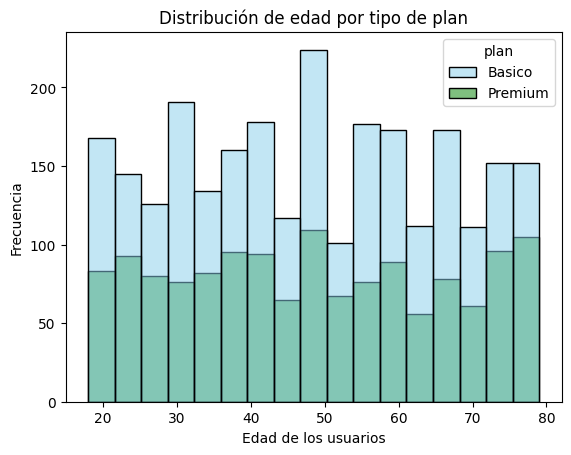

In [35]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile,
    x = "age",
    hue = "plan",
    palette =["skyblue", "green"]
)

plt.title("Distribución de edad por tipo de plan")
plt.xlabel("Edad de los usuarios")
plt.ylabel("Frecuencia")
plt.show()

💡Insights: 
- Distribución equilibrada por la edad de los usuarios, las edades oscilan entre los 18 y 79 años, sin reflejarse un sesgo evidente hacia edades jóvenes o avanzadas.

El plan Basico presenta una mayor frecuencia de usuarios en la mayoría de los rangos de edad, especialmente en el grupo de los 48 a 50 años presentando el pico mas alto, mientras que el plan Premium mantiene un patrón de distribución similar, aunque con frecuencias inferiores.

En general, no se identifica una concentración dominante en un grupo de edad específico ni diferencias marcadas en la forma de las distribuciones entre ambos planes, 

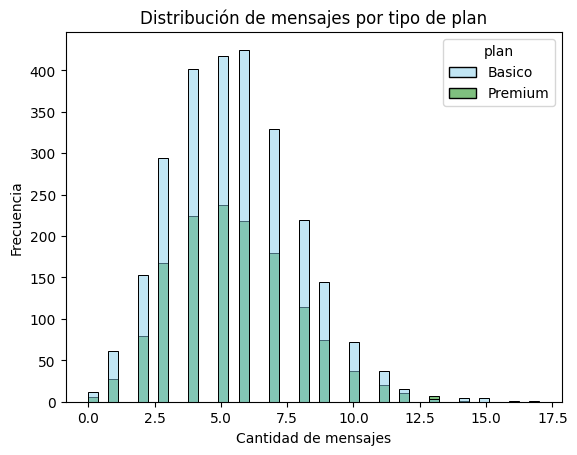

In [36]:
# Histograma para visualizar la cant_mensajes
sns.histplot(
    data=user_profile,
    x = "cant_mensajes",
    hue = "plan",
    palette = ["skyblue", "green"]
)

plt.title("Distribución de mensajes por tipo de plan")
plt.xlabel("Cantidad de mensajes")
plt.ylabel("Frecuencia")
plt.show()

💡Insights: 
- Se observa una distribucion con un ligero sesgo hacia la derecha, indicando que la mayoria de usuarios se concentra en cantidades entre 3 y 8 mensajes, y las mayores frecuencias alrededor de 5 y 6 mensajes.

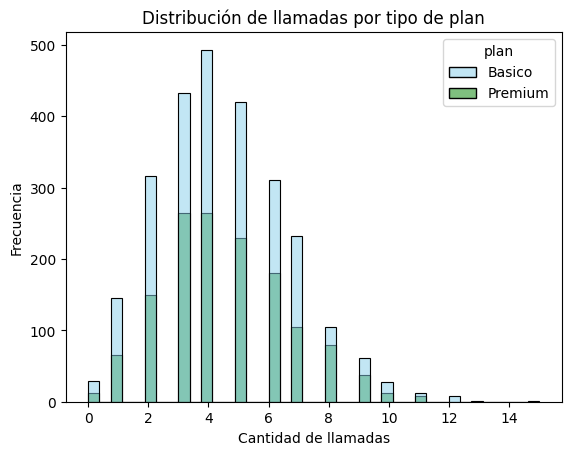

In [37]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data = user_profile,
    x = "cant_llamadas",
    hue = "plan",
    palette = ["skyblue", "green"]
)

plt.title("Distribución de llamadas por tipo de plan")
plt.xlabel("Cantidad de llamadas")
plt.ylabel("Frecuencia")
plt.show()

💡Insights: 
- Distribución sesgo hacia la derecha, mayoría de los usuarios se concentra en cantidades moderadas de llamadas, mientras que una proporción pequeña registra valores superiores, alcanzando aproximadamente 15 llamadas. La mayor parte de los usuarios registra aproximadamente entre 2 y 7 llamadas. La frecuencia más alta se encuentra alrededor de las 4 llamadas, especialmente en el plan Basico. 

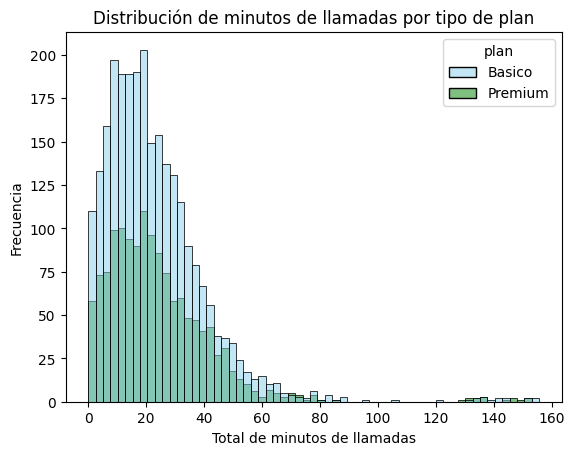

In [38]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(
    data = user_profile,
    x = "cant_minutos_llamada",
    hue = "plan",
    palette = ["skyblue", "green"]
)

plt.title("Distribución de minutos de llamadas por tipo de plan")
plt.xlabel("Total de minutos de llamadas")
plt.ylabel("Frecuencia")
plt.show()

💡Insights: 
- Distribucion sesgo a la derecha claramente marcada, lo que nos indica que la mayoria de usuarios consume pocos minutos, mientras que el grupo reducido registra consumos de 155 minutos, lo que nos indica que se deben evaluar porsibles valores atipicos. La distribución de minutos de llamadas presenta una concentración de usuarios principalmente entre 5 y 35 minutos, con las mayores frecuencias alrededor de los 10 a 20 minutos.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

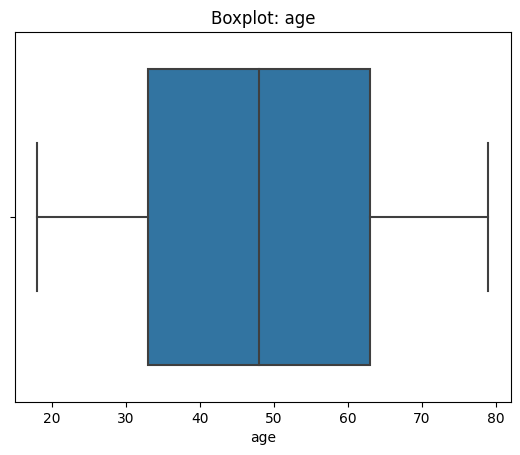

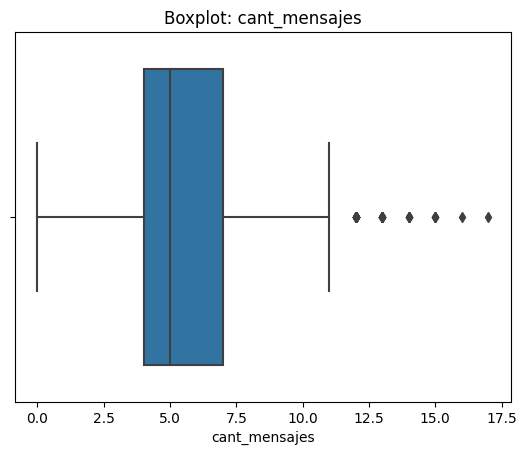

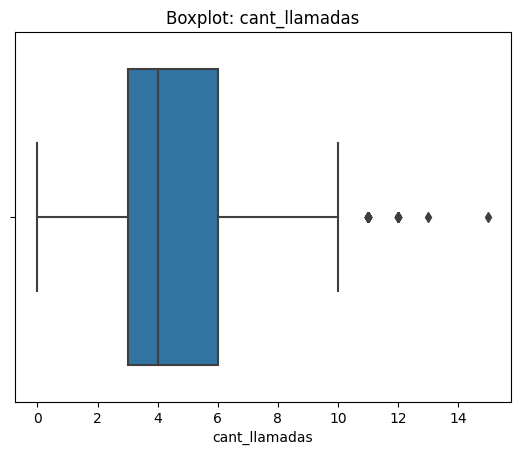

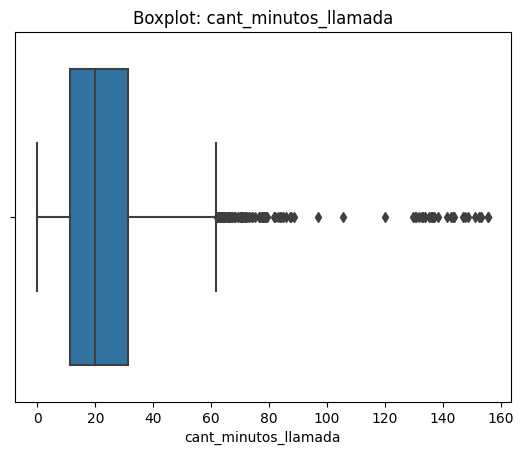

In [39]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.show()

##### 💡Insights: 
- Age: No se identifican outliers; las edades se distribuyen aproximadamente entre 18 y 79 años, con una mediana cercana a 48 años.
- cant_mensajes: Se identifican outliers superiores a 11 mensajes, alcanzando valores de hasta 17 mensajes por usuario.
- cant_llamadas: Se observan outliers superiores a 10 llamadas, con valores extremos que alcanzan las 15 llamadas.
- cant_minutos_llamada: Presenta numerosos outliers superiores a aproximadamente 62 minutos, alcanzando consumos cercanos a 155 minutos.

In [41]:
# Calcular límites con el método IQR
columnas_limites = [
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]
for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)

    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR

    print(col)
    print("Límite superior:", limite_superior)
    print("Cantidad de outliers:", (user_profile[col] > limite_superior).sum())
    print()


cant_mensajes
Límite superior: 11.5
Cantidad de outliers: 46

cant_llamadas
Límite superior: 10.5
Cantidad de outliers: 30

cant_minutos_llamada
Límite superior: 61.8575
Cantidad de outliers: 109



In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? Se mantienen los 46 outliers superiores al límite IQR de 11.5, ya que podrían representar usuarios con mayor actividad de mensajería y no necesariamente errores.
- cant_llamadas: mantener o no outliers, porqué? Se conservan los 30 outliers superiores al límite de 10.5, debido a que podrían corresponder a usuarios con una frecuencia de llamadas más elevada.
- cant_minutos_llamada: mantener o no outliers, porqué? Se mantienen los 109 outliers superiores a 61.86 minutos, ya que podrían reflejar patrones legítimos de alto consumo, relevantes para el análisis del comportamiento de los clientes.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [42]:
# Crear columna grupo_uso
def clasificar_uso(row):
    llamadas = row['cant_llamadas']
    mensajes = row['cant_mensajes']

    if llamadas < 5 and mensajes < 5:
        return 'Bajo uso'
    elif llamadas < 10 and mensajes < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

In [43]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [44]:
# Crear columna grupo_edad
def clasificar_edad(row):
    edad = row['age']

    if edad < 30:
        return 'Joven'
    elif edad < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)

In [45]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

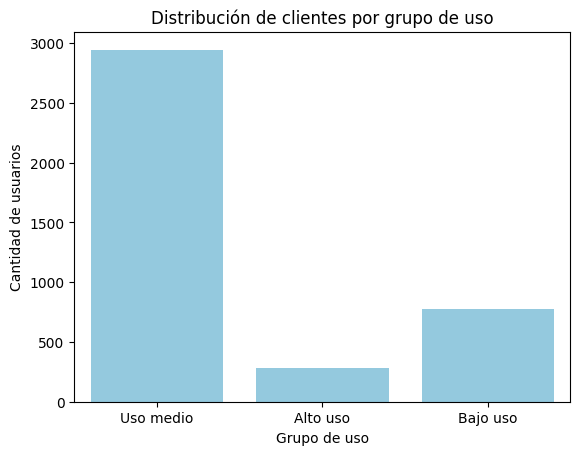

In [46]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', color='skyblue')

plt.title('Distribución de clientes por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')

plt.show()

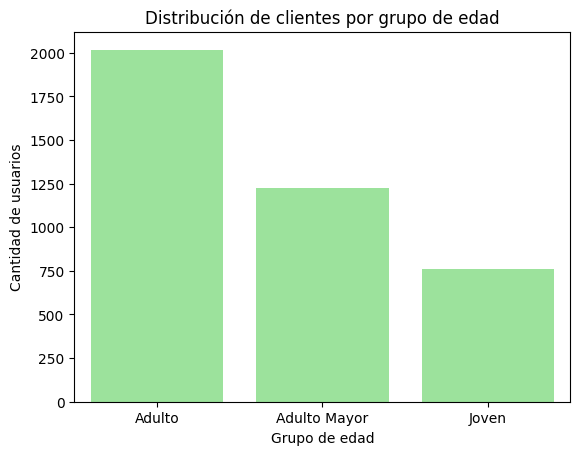

In [47]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', color='lightgreen')

plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')

plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Se analizaron tres fuentes: users_latam.csv (4,000 clientes), usage.csv (40,000 registros de actividad) y plans.csv (2 planes comerciales). Se identificaron 55 edades inválidas (-999, 1.38%), 469 ciudades ausentes (11.73%) y 96 ciudades con el valor ? (2.40%).
- Se detectaron 40 fechas de registro correspondientes a 2026 (1% de los clientes), posteriores al período de actividad analizado (2024), y 50 fechas de uso ausentes (0.13% de los registros).
- La limpieza se organizó mediante un pipeline de validación, transformación y tratamiento de datos: sustitución de edades inválidas por la mediana, estandarización de ciudades desconocidas como valores ausentes y conversión de fechas inconsistentes a NaT.
- Se conservaron los valores ausentes estructurales de duration y length, ya que corresponden a tipos de actividad diferentes: las llamadas registran duración y los mensajes registran longitud. Posteriormente, se agregaron los consumos por user_id y se integraron con los datos de clientes para construir user_profile.
- El perfil integrado contiene 3,999 usuarios. Se recomienda investigar el usuario sin registros de actividad antes de interpretar la ausencia de consumo como abandono del servicio.

🔍 **Segmentos por Edad**
- La edad presenta una distribución aproximadamente uniforme entre 18 y 79 años, sin valores atípicos en el boxplot. La media es de 48.14 años, la mediana de 48 y el rango intercuartílico de 33 a 63 años.
- El grupo Adulto (30–59 años) concentra 2,017 usuarios (50.4%), seguido de Adulto Mayor con 1,222 (30.6%) y Joven con 760 (19.0%).
- El consumo medio predomina en los tres grupos de edad: aproximadamente 72.6% de los jóvenes, 74.4% de los adultos y 72.9% de los adultos mayores. Esto indica que, bajo las reglas de segmentación utilizadas, no se observan diferencias marcadas en la distribución del nivel de uso por edad.

📊 **Segmentos por Nivel de Uso**
- Mensajes: la media es de 5.52 y la mediana de 5 por usuario. El histograma muestra una distribución ligeramente asimétrica hacia la derecha, con mayor concentración entre 3 y 8 mensajes.
- Llamadas: se registran 4.48 llamadas en promedio y una mediana de 4. La distribución presenta asimetría positiva, con mayor concentración entre 2 y 7 llamadas.
- Minutos de llamada: el promedio acumulado es de 23.32 minutos y la mediana de 19.78. La distribución presenta una asimetría positiva más pronunciada, debido a usuarios con duraciones considerablemente superiores al consumo habitual.
- Segmentación: Uso medio concentra 2,943 usuarios (73.6%), Bajo uso 778 (19.5%) y Alto uso 278 (7.0%). El predominio de Uso medio representa una oportunidad para fortalecer la fidelización, mientras que Alto uso constituye un segmento de interés para evaluar servicios diferenciados.
- Los histogramas por plan muestran perfiles de consumo similares entre Básico y Premium. Aunque Básico presenta frecuencias absolutas superiores, esto debe interpretarse considerando que tiene una base de clientes mayor, y no como evidencia directa de mayor intensidad de consumo.

➡️ Esto sugiere que la base de clientes presenta un comportamiento predominantemente moderado, con un grupo reducido de usuarios que concentra consumos superiores a los habituales. Las distribuciones asimétricas muestran que los promedios, especialmente en minutos, pueden verse influenciados por los consumos extremos.
El segmento de Uso medio ofrece oportunidades de fidelización por su tamaño, mientras que Alto uso puede ser relevante para desarrollar servicios personalizados. Sin embargo, un mayor consumo no implica necesariamente mayor rentabilidad; esta debe validarse mediante ingresos, costos y características de los planes contratados.

💡 **Recomendaciones**
- Fidelización: priorizar campañas y beneficios para los clientes de Uso medio, que representan el 73.6% de la base analizada.
- Personalización: evaluar paquetes flexibles para usuarios de Alto uso, considerando minutos adicionales, mensajes y beneficios ajustados a su comportamiento real.
- Optimización de planes: contrastar el consumo observado con los beneficios de Básico y Premium para identificar oportunidades de mejora, evitando proponer incrementos de capacidad sin comprobar primero su necesidad.
- Monitoreo de outliers: implementar controles periódicos mediante IQR para identificar cambios de consumo, posibles inconsistencias y usuarios que requieran atención comercial.
- Calidad de datos: mantener un pipeline reproducible que valide edades, ciudades, fechas y registros de actividad antes de actualizar los indicadores.
- Análisis futuro: incorporar ingresos, costos, permanencia y abandono de clientes para evaluar la rentabilidad de los segmentos y fundamentar decisiones comerciales.
  

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.

### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`